# Feature Engineering

In [11]:
import pandas as pd
import numpy as np

df = pd.read_csv('/Users/david/Desktop/ml-ufc/data/ufc-master.csv')

fighter_features = [
    "age",
    "Height_cms",
    "Reach_cms",
    "wins",
    "losses",
    "current_win_streak",
    "current_lose_streak",
    "total_rounds_fought",
    "total_title_bouts",
    "avg_SIG_STR_pct",
    "avg_TD_landed",
    "avg_TD_pct",
    "avg_SUB_ATT",
    "win_by_KO/TKO",
    "win_by_Submission",
    "Stance"
]

features = (['R_' + feature for feature in fighter_features] + ['B_' + feature for feature in fighter_features]
            + ["weight_class", "title_bout", "no_of_rounds"])

In [12]:
def create_features(df):
    df = df.copy()

    df["age_diff"] = df["R_age"] - df["B_age"]

    df["R_Reach_cms"] = df["R_Reach_cms"].replace(0, np.nan)
    df["B_Reach_cms"] = df["B_Reach_cms"].replace(0, np.nan)

    df["reach_diff"] = (
        df["R_Reach_cms"] - df["B_Reach_cms"]
    )

    df["height_diff"] = (
        df["R_Height_cms"] - df["B_Height_cms"]
    )

    df["win_streak_diff"] = (
        df["R_current_win_streak"]
        - df["B_current_win_streak"]
    )

    df['lose_streak_diff'] = (
        df['R_current_lose_streak']
        - df['B_current_lose_streak']
    )

    df['wins_diff'] = (
        df['R_wins'] - df['B_wins']
    )

    df['losses_diff'] = (
        df['R_losses'] - df['B_losses']
    )

    r_total = df["R_wins"] + df["R_losses"] + df["R_draw"]
    b_total = df["B_wins"] + df["B_losses"] + df["B_draw"]

    df['R_is_debutant'] = (r_total == 0).astype(int)
    df['B_is_debutant'] = (b_total == 0).astype(int)

    df["experience_diff"] = r_total - b_total

    r_winrate = (df["R_wins"] / r_total).where(r_total > 0)
    b_winrate = (df["B_wins"] / b_total).where(b_total > 0)

    df["win_rate_diff"] = r_winrate - b_winrate


    return df

In [13]:
df_clean = df[df['Winner'].isin(['Red','Blue'])].copy() # skip draw, no contest
df_clean['date'] = pd.to_datetime(df_clean['date']) #make date from string to date
df_clean = df_clean.sort_values("date") #sort by date

split_idx = int(len(df_clean) * 0.8) #80% of old fight, and 20% for final test

cutoff_date = df_clean.iloc[split_idx]["date"]

train_df = df_clean[df_clean["date"] < cutoff_date].copy()
test_df = df_clean[df_clean["date"] >= cutoff_date].copy()

print("Train:", len(train_df))
print("Test:", len(test_df))

print("Last train date:", train_df["date"].max())
print("First test date:", test_df["date"].min())

assert train_df["date"].max() < test_df["date"].min()


Train: 5726
Test: 1443
Last train date: 2023-05-20 00:00:00
First test date: 2023-06-03 00:00:00


In [14]:
train_df = create_features(train_df)
test_df = create_features(test_df)


In [15]:
new_features = [
    "age_diff",
    "reach_diff",
    "height_diff",
    "win_streak_diff",
    "lose_streak_diff",
    "wins_diff",
    "losses_diff",
    "experience_diff",
    "win_rate_diff",
    'R_is_debutant',
    'B_is_debutant'
]

train_df[new_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age_diff,5726.0,0.566364,5.162550,-16.00,-3.000000,0.5,4.00000,17.00
reach_diff,5725.0,0.169230,8.308528,-30.48,-5.080000,0.0,5.08000,33.02
height_diff,5726.0,-0.040168,6.383849,-30.48,-5.080000,0.0,5.08000,33.02
win_streak_diff,5726.0,0.153860,1.807285,-10.00,0.000000,0.0,1.00000,16.00
lose_streak_diff,5726.0,0.126441,1.006569,-5.00,0.000000,0.0,1.00000,6.00
wins_diff,5726.0,1.463500,4.092850,-23.00,0.000000,1.0,3.00000,28.00
losses_diff,5726.0,0.703633,2.933739,-14.00,-1.000000,0.0,2.00000,18.00
experience_diff,5726.0,2.173594,6.586654,-27.00,-1.000000,1.0,5.00000,43.00
win_rate_diff,4510.0,0.045181,0.314184,-1.00,-0.141026,0.0,0.21721,1.00
R_is_debutant,5726.0,0.077366,0.267195,0.00,0.000000,0.0,0.00000,1.00


In [16]:
missing_values = train_df[new_features].isna().sum()

missing_percentage = (
    train_df[new_features].isna().mean() * 100
)

print("Missing values:")
print(missing_values)

print("\nMissing percentage:")
print(missing_percentage)

Missing values:
age_diff               0
reach_diff             1
height_diff            0
win_streak_diff        0
lose_streak_diff       0
wins_diff              0
losses_diff            0
experience_diff        0
win_rate_diff       1216
R_is_debutant          0
B_is_debutant          0
dtype: int64

Missing percentage:
age_diff             0.000000
reach_diff           0.017464
height_diff          0.000000
win_streak_diff      0.000000
lose_streak_diff     0.000000
wins_diff            0.000000
losses_diff          0.000000
experience_diff      0.000000
win_rate_diff       21.236465
R_is_debutant        0.000000
B_is_debutant        0.000000
dtype: float64


In [17]:
import numpy as np

inf_count = np.isinf(
    train_df[new_features].to_numpy(dtype=float)
).sum()

print("Infinite values:", inf_count)

Infinite values: 0


In [18]:
idx = train_df['reach_diff'].idxmax()

train_df.loc[idx,
             [
    "R_fighter",
    "B_fighter",
    "R_Reach_cms",
    "B_Reach_cms",
    "reach_diff"
             ]]

R_fighter         Miguel Torres
B_fighter      Antonio Banuelos
R_Reach_cms              193.04
B_Reach_cms              160.02
reach_diff                33.02
Name: 6940, dtype: object

In [19]:
print((train_df["R_Reach_cms"] == 0).sum())
print((train_df["B_Reach_cms"] == 0).sum())

0
0


### Data Quality — Invalid Reach Values

#### Problem

During feature validation, an extreme
reach difference of 187.96 cm was detected.

Fight:
- Red: Giga Chikadze
- Blue: Irwin Rivera

Original values:
- R_Reach_cms: 187.96
- B_Reach_cms: 0.0

#### Investigation

- Zero reach values in Red: 0
- Zero reach values in Blue: 1

A reach value of zero is physically impossible.

This suggests a missing value encoded as zero.

#### Solution

Replace invalid zero reach measurements
with NaN before feature engineering.

Missing values will be handled using
SimpleImputer fitted on training data.


In [20]:
print(train_df["reach_diff"].isna().sum())
print(train_df["reach_diff"].describe())

1
count    5725.000000
mean        0.169230
std         8.308528
min       -30.480000
25%        -5.080000
50%         0.000000
75%         5.080000
max        33.020000
Name: reach_diff, dtype: float64


In [21]:
r_total = (
    train_df["R_wins"] +
    train_df["R_losses"] +
    train_df["R_draw"]
)

b_total = (
    train_df["B_wins"] +
    train_df["B_losses"] +
    train_df["B_draw"]
)

print("Red debutants:", (r_total == 0).sum())
print("Blue debutants:", (b_total == 0).sum())

print(
    "Fights with at least one debutant:",
    ((r_total == 0) | (b_total == 0)).sum()
)

Red debutants: 443
Blue debutants: 1050
Fights with at least one debutant: 1216


In [22]:
debutant_mask = (r_total == 0) | (b_total == 0)
missing_mask = train_df["win_rate_diff"].isna()

print((debutant_mask == missing_mask).all())

True


In [23]:
quality_report = pd.DataFrame({
    "dtype": train_df[features].dtypes,
    "missing_count": train_df[features].isna().sum(),
    "missing_pct": train_df[features].isna().mean() * 100
})

quality_report.sort_values(
    "missing_pct",
    ascending=False
)

,dtype,missing_count,missing_pct
B_avg_TD_pct,float64,842,14.704855
B_avg_TD_landed,float64,833,14.547677
B_avg_SUB_ATT,float64,832,14.530213
B_avg_SIG_STR_pct,float64,765,13.360112
R_avg_TD_pct,float64,367,6.409361
R_avg_TD_landed,float64,357,6.234719
R_avg_SIG_STR_pct,float64,357,6.234719
R_avg_SUB_ATT,float64,357,6.234719
B_Stance,str,2,0.034928
B_Reach_cms,float64,1,0.017464


In [24]:
all_features = new_features + features

X_train = (train_df[all_features])
y_train = (train_df['Winner'] == 'Red').astype(int)

X_test = (test_df[all_features])
y_test = (test_df['Winner'] == 'Red').astype(int)

In [25]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("Features:", len(all_features))

X_train: (5726, 46)
y_train: (5726,)
X_test: (1443, 46)
y_test: (1443,)
Features: 46


In [26]:
print("Debutant features:",
      "R_is_debutant" in all_features,
      "B_is_debutant" in all_features)

print("Duplicates:",
      len(all_features) - len(set(all_features)))

print("Total:", len(all_features))

Debutant features: True True
Duplicates: 0
Total: 46


# Next step

In [27]:
X_train.isna().sum()

age_diff                    0
reach_diff                  1
height_diff                 0
win_streak_diff             0
lose_streak_diff            0
wins_diff                   0
losses_diff                 0
experience_diff             0
win_rate_diff            1216
R_is_debutant               0
B_is_debutant               0
R_age                       0
R_Height_cms                0
R_Reach_cms                 0
R_wins                      0
R_losses                    0
R_current_win_streak        0
R_current_lose_streak       0
R_total_rounds_fought       0
R_total_title_bouts         0
R_avg_SIG_STR_pct         357
R_avg_TD_landed           357
R_avg_TD_pct              367
R_avg_SUB_ATT             357
R_win_by_KO/TKO             0
R_win_by_Submission         0
R_Stance                    0
B_age                       0
B_Height_cms                0
B_Reach_cms                 1
B_wins                      0
B_losses                    0
B_current_win_streak        0
B_current_

In [28]:
X_train['title_bout'] = X_train['title_bout'].astype(int)
X_test['title_bout'] = X_test['title_bout'].astype(int)

In [29]:
cat_val = X_train.select_dtypes(include=['object','string'])
num_val = X_train.select_dtypes(exclude=['object', 'string'])

print(num_val.columns)
print(cat_val.columns)


Index(['age_diff', 'reach_diff', 'height_diff', 'win_streak_diff',
       'lose_streak_diff', 'wins_diff', 'losses_diff', 'experience_diff',
       'win_rate_diff', 'R_is_debutant', 'B_is_debutant', 'R_age',
       'R_Height_cms', 'R_Reach_cms', 'R_wins', 'R_losses',
       'R_current_win_streak', 'R_current_lose_streak',
       'R_total_rounds_fought', 'R_total_title_bouts', 'R_avg_SIG_STR_pct',
       'R_avg_TD_landed', 'R_avg_TD_pct', 'R_avg_SUB_ATT', 'R_win_by_KO/TKO',
       'R_win_by_Submission', 'B_age', 'B_Height_cms', 'B_Reach_cms', 'B_wins',
       'B_losses', 'B_current_win_streak', 'B_current_lose_streak',
       'B_total_rounds_fought', 'B_total_title_bouts', 'B_avg_SIG_STR_pct',
       'B_avg_TD_landed', 'B_avg_TD_pct', 'B_avg_SUB_ATT', 'B_win_by_KO/TKO',
       'B_win_by_Submission', 'title_bout', 'no_of_rounds'],
      dtype='str')
Index(['R_Stance', 'B_Stance', 'weight_class'], dtype='str')


In [30]:
print("Numerical:", num_val.shape[1])
print("Categorical:", cat_val.shape[1])
print("Total:", num_val.shape[1] + cat_val.shape[1])

Numerical: 43
Categorical: 3
Total: 46


In [31]:
numerical_features = num_val.columns.tolist()
categorical_features = cat_val.columns.tolist()

print(len(numerical_features))
print(len(categorical_features))

43
3


In [32]:
some_table = num_val.describe().T
some_table[['mean', 'count', '50%', 'std']]

,mean,count,50%,std
age_diff,0.566364,5726.0,0.5000,5.162550
reach_diff,0.169230,5725.0,0.0000,8.308528
height_diff,-0.040168,5726.0,0.0000,6.383849
win_streak_diff,0.153860,5726.0,0.0000,1.807285
lose_streak_diff,0.126441,5726.0,0.0000,1.006569
wins_diff,1.463500,5726.0,1.0000,4.092850
losses_diff,0.703633,5726.0,0.0000,2.933739
experience_diff,2.173594,5726.0,1.0000,6.586654
win_rate_diff,0.045181,4510.0,0.0000,0.314184
R_is_debutant,0.077366,5726.0,0.0000,0.267195


In [33]:
nulls_num = num_val.isnull().sum()
nulls_num_v = nulls_num[nulls_num > 0]
nulls_num_columns = nulls_num_v.index.tolist()


num_val[nulls_num_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
reach_diff,5725.0,0.169230,8.308528,-30.48,-5.080000,0.0000,5.08000,33.02
win_rate_diff,4510.0,0.045181,0.314184,-1.00,-0.141026,0.0000,0.21721,1.00
R_avg_SIG_STR_pct,5369.0,0.457319,0.101621,0.00,0.400000,0.4560,0.51200,1.00
R_avg_TD_landed,5369.0,1.371021,1.288172,0.00,0.437500,1.0000,2.00000,12.50
R_avg_TD_pct,5359.0,0.336706,0.222793,0.00,0.193000,0.3310,0.46800,1.00
R_avg_SUB_ATT,5369.0,0.523887,0.656499,0.00,0.000000,0.3333,0.80000,8.30
B_Reach_cms,5725.0,182.345417,10.810446,147.32,175.260000,182.8800,190.50000,213.36
B_avg_SIG_STR_pct,4961.0,0.449342,0.114817,0.00,0.393000,0.4570,0.51000,1.00
B_avg_TD_landed,4893.0,1.292521,1.349580,0.00,0.285700,1.0000,1.91000,10.86
B_avg_TD_pct,4884.0,0.319814,0.241865,0.00,0.133000,0.3300,0.47000,1.00


<Axes: >

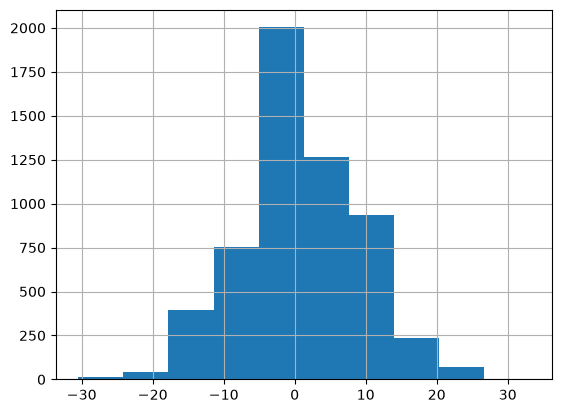

In [34]:
num_val['reach_diff'].hist() #mean can be good

<Axes: >

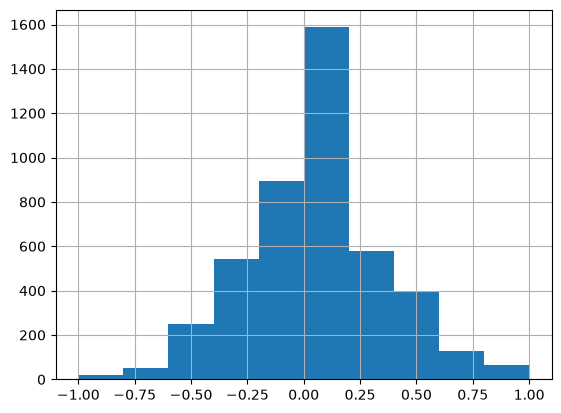

In [35]:
num_val['win_rate_diff'].hist() # mean

<Axes: >

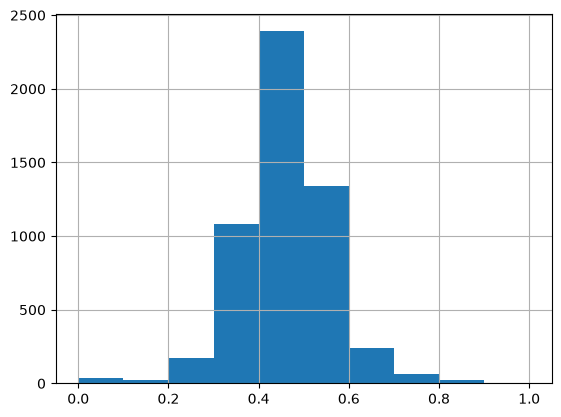

In [36]:
num_val['R_avg_SIG_STR_pct'].hist()# mean or median, they barely same values

<Axes: >

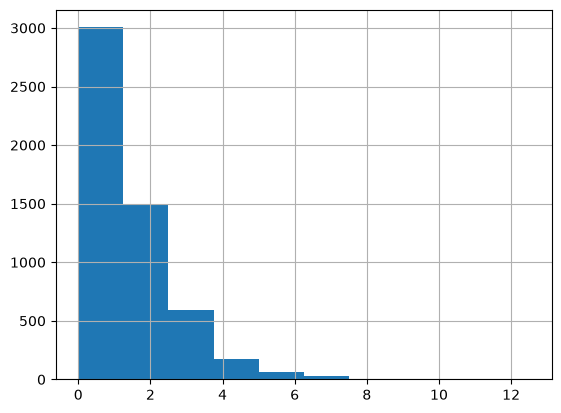

In [37]:
num_val['R_avg_TD_landed'].hist() # right skewed median

<Axes: >

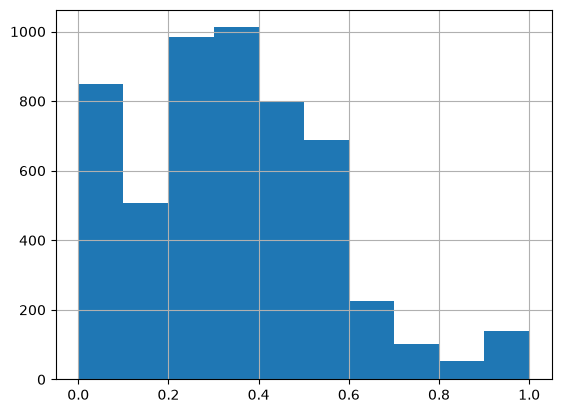

In [38]:
num_val['R_avg_TD_pct'].hist()# median

<Axes: >

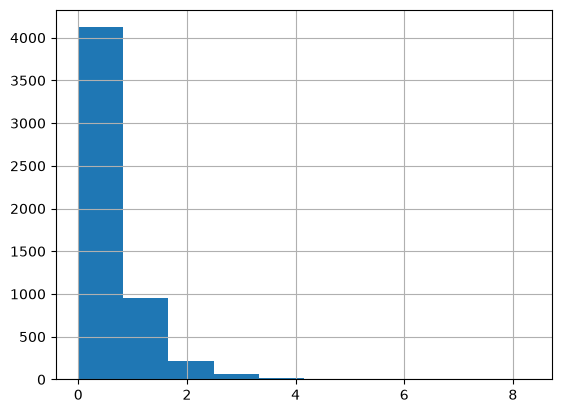

In [39]:
num_val['R_avg_SUB_ATT'].hist()#median

<Axes: >

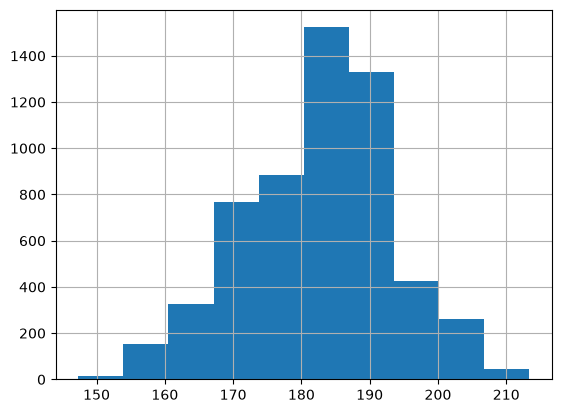

In [40]:
num_val['B_Reach_cms'].hist() #median or mean

<Axes: >

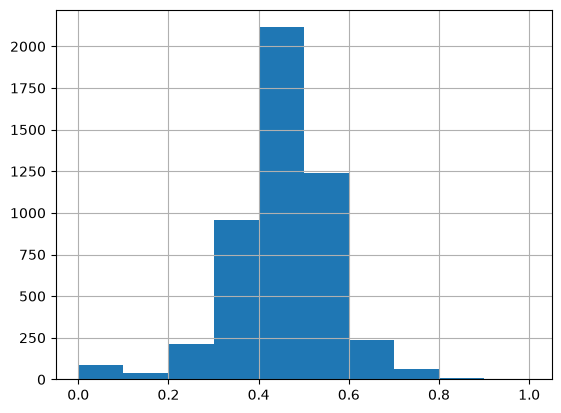

In [41]:
num_val['B_avg_SIG_STR_pct'].hist() #mean or median

<Axes: >

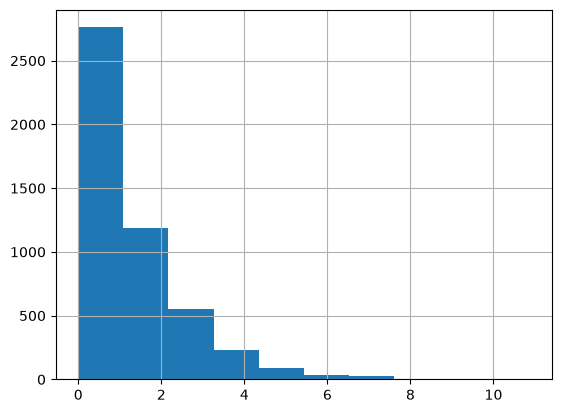

In [42]:
num_val['B_avg_TD_landed'].hist() # median

<Axes: >

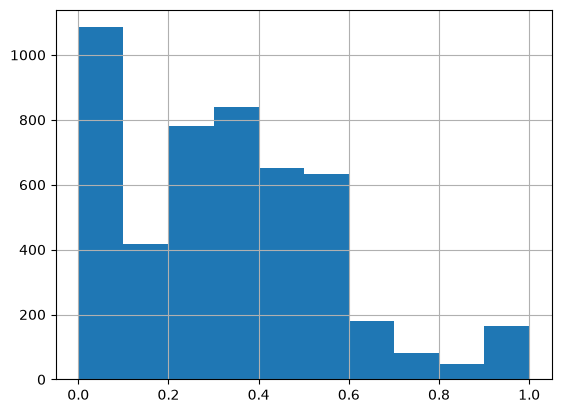

In [43]:
num_val['B_avg_TD_pct'].hist() # median

<Axes: >

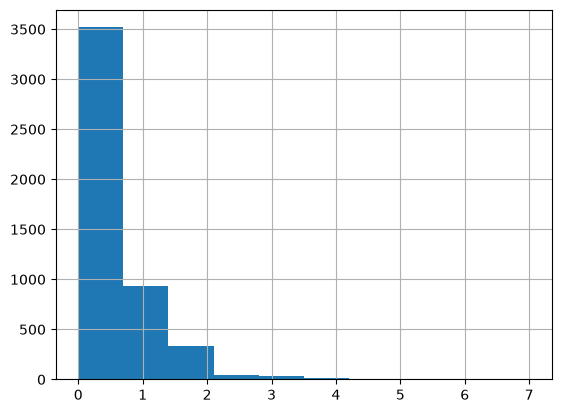

In [44]:
num_val['B_avg_SUB_ATT'].hist() # median

In [45]:
nulls_cat = cat_val.isnull().sum()
nulls_cat


R_Stance        0
B_Stance        2
weight_class    0
dtype: int64

### Imputation Strategy — Final Decision

#### Numerical Features

Mean imputation:
- reach_diff
- B_Reach_cms
- R_avg_SIG_STR_pct
- B_avg_SIG_STR_pct

Median imputation:
- win_rate_diff
- R_avg_TD_landed / B_avg_TD_landed
- R_avg_TD_pct / B_avg_TD_pct
- R_avg_SUB_ATT / B_avg_SUB_ATT

#### Categorical Features

Most-frequent imputation for missing stances.

#### Reasoning

- Mean is suitable for approximately symmetric
  distributions without severe outliers.
- Median is more robust to skewness and outliers.
- Missing UFC statistics do not necessarily mean zero.
- Debutant indicators preserve some information
  about missing historical performance.

#### Important

All imputation statistics must be learned
from training data inside the ML Pipeline.

The chosen strategies are initial hypotheses
and may be compared during validation.

In [46]:
mean_features = ['reach_diff', 'B_Reach_cms', 'R_avg_SIG_STR_pct', 'B_avg_SIG_STR_pct']
median_features = [feature for feature in numerical_features if feature not in mean_features]
mode_feature = cat_val.columns.tolist()


print(len(mean_features))
print(len(median_features))
print(len(categorical_features))


4
39
3


In [47]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


num_pipeline_mean = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('std_scaler', StandardScaler())
])

num_pipeline_median = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('std_scaler', StandardScaler())
])

cat_pipeline_mode = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot', OneHotEncoder(handle_unknown='ignore'))
])

full_pipeline = ColumnTransformer([
    ('num_mean', num_pipeline_mean, mean_features),
    ('num_median', num_pipeline_median, median_features),
    ('cat_mode', cat_pipeline_mode, mode_feature)
])

selected_features = mean_features + median_features + mode_feature

print("Duplicates:", len(selected_features) - len(set(selected_features)))
print("Missing:", set(X_train.columns) - set(selected_features))



Duplicates: 0
Missing: set()


# Train validation split

The outer date-based split contains 5,726 training fights through 2023-05-20 and 1,443 test fights from 2023-06-03 onward.

The inner split also keeps complete dates together: 4,576 training fights through 2021-02-13 and 1,150 validation fights from 2021-02-20 through 2023-05-20. Training and validation dates no longer overlap.

The four expanding cross-validation folds below split unique dates within the inner training partition. All four boundary checks return `Valid: True`.

In [48]:
val_position = int(len(train_df) * 0.8)
val_cutoff_date = train_df.iloc[val_position]["date"]

train_mask = train_df["date"] < val_cutoff_date
val_mask = train_df["date"] >= val_cutoff_date

X_tr = X_train.loc[train_mask].copy()
X_val = X_train.loc[val_mask].copy()

y_tr = y_train.loc[train_mask].copy()
y_val = y_train.loc[val_mask].copy()

last_train_date = train_df.loc[train_mask, "date"].max()
first_val_date = train_df.loc[val_mask, "date"].min()

print("Inner train:", len(X_tr))
print("Validation:", len(X_val))
print("Last train date:", last_train_date)
print("First validation date:", first_val_date)

assert last_train_date < first_val_date
assert not X_tr.index.intersection(X_val.index).size
assert len(X_tr) + len(X_val) == len(X_train)

Inner train: 4576
Validation: 1150
Last train date: 2021-02-13 00:00:00
First validation date: 2021-02-20 00:00:00


In [49]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

dates_tr = train_df.loc[X_tr.index, "date"].reset_index(drop=True)

unique_dates = (
    dates_tr.drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

date_tscv = TimeSeriesSplit(n_splits=4)

cv_splits = []

for fold, (train_dates_idx, val_dates_idx) in enumerate(
    date_tscv.split(unique_dates), 1
):
    train_dates = unique_dates.iloc[train_dates_idx]
    val_dates = unique_dates.iloc[val_dates_idx]

    train_idx = np.flatnonzero(dates_tr.isin(train_dates))
    val_idx_cv = np.flatnonzero(dates_tr.isin(val_dates))

    cv_splits.append((train_idx, val_idx_cv))

    last_train = dates_tr.iloc[train_idx].max()
    first_val = dates_tr.iloc[val_idx_cv].min()

    assert last_train < first_val

    print(
        f"Fold {fold}: "
        f"{last_train.date()} -> {first_val.date()}"
    )
    print("Valid:", last_train < first_val)

Fold 1: 2013-01-26 -> 2013-02-02
Valid: True
Fold 2: 2015-02-28 -> 2015-03-14
Valid: True
Fold 3: 2017-03-04 -> 2017-03-11
Valid: True
Fold 4: 2019-03-16 -> 2019-03-23
Valid: True


# Logistic Regression Evaluation

In [50]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV



lr_pipeline = Pipeline([
    ('full', full_pipeline),
    ('model', LogisticRegression(max_iter=2000,random_state=42))
])

param_grid = [
    {
    'model__C' : [0.001,0.01, 0.1, 1.0, 10],
    'model__penalty':['l1', 'l2'],
    'model__solver':['liblinear'],
    'model__class_weight': [None, 'balanced']
    },
    {
     'model__penalty': ['l2', None],
     'model__C': [0.001, 0.01, 0.1, 1, 10],
     'model__solver': ['lbfgs'],
     'model__class_weight': [None, 'balanced'],
     'model__max_iter': [1000]   
    }
]

grid_searc_lr = GridSearchCV(lr_pipeline, param_grid, cv=cv_splits, scoring='neg_log_loss', n_jobs=-1)

grid_searc_lr.fit(X_tr, y_tr)

print("Best params:", grid_searc_lr.best_params_)
print("Best CV Log Loss:", -grid_searc_lr.best_score_)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio

Best params: {'model__C': 0.01, 'model__class_weight': None, 'model__max_iter': 1000, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Best CV Log Loss: 0.662168355721352


/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [51]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    log_loss,
    precision_score,
    recall_score,
    f1_score
)

best_lr = grid_searc_lr.best_estimator_

y_pred = best_lr.predict(X_val)
y_proba = best_lr.predict_proba(X_val)[:, 1]

print("Validation Accuracy:", accuracy_score(y_val, y_pred))
print("Validation ROC-AUC:", roc_auc_score(y_val, y_proba))
print("Validation Log Loss:", log_loss(y_val, y_proba))
print("Validation Precision:", precision_score(y_val, y_pred))
print("Validation Recall:", recall_score(y_val, y_pred))
print("Validation f1-score:", f1_score(y_val, y_pred))

Validation Accuracy: 0.6095652173913043
Validation ROC-AUC: 0.6375280781164783
Validation Log Loss: 0.652326115190918
Validation Precision: 0.6180555555555556
Validation Recall: 0.8177641653905053
Validation f1-score: 0.7040210942649967


In [52]:
import numpy as np

baseline_proba = np.full(len(y_val), y_tr.mean())

print("Baseline Log Loss:", log_loss(y_val, baseline_proba))

Baseline Log Loss: 0.6845710544876861


In [53]:
from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_val, y_pred))

print(classification_report(
    y_val,
    y_pred,
    target_names=["Blue", "Red"]
))

[[167 330]
 [119 534]]
              precision    recall  f1-score   support

        Blue       0.58      0.34      0.43       497
         Red       0.62      0.82      0.70       653

    accuracy                           0.61      1150
   macro avg       0.60      0.58      0.57      1150
weighted avg       0.60      0.61      0.58      1150



In [54]:
baseline_pred = np.ones(len(y_val), dtype=int)

print(
    "Baseline Accuracy:",
    accuracy_score(y_val, baseline_pred)
)

Baseline Accuracy: 0.5678260869565217


### Logistic Regression — Final Validation Analysis

#### Results

- Accuracy: 60.96%
- ROC-AUC: 0.6375
- Log Loss: 0.652326
- Precision (Red): 61.81%
- Recall (Red): 81.78%
- F1-score (Red): 70.40%
- Best CV Log Loss: 0.662168

#### Confusion Matrix

| Actual / Predicted | Blue | Red |
|---|---:|---:|
| Blue | 167 | 330 |
| Red | 119 | 534 |

Validation support: 497 Blue and 653 Red fights, 1,150 total.

#### Baseline Comparison

- Always-Red Accuracy: 56.78%
- Logistic Regression Accuracy: 60.96%
- Constant-probability Baseline Log Loss: 0.684571
- Logistic Regression Log Loss: 0.652326

#### Key Findings

Logistic Regression outperformed both baseline comparisons on this date-separated validation period. At threshold 0.50, Red recall (81.78%) is substantially higher than Blue recall (33.60%). Threshold selection is evaluated separately below.

# Support Vector Machine Evaluation

In [55]:
from sklearn.svm import SVC


svc_pipeline = Pipeline([
    ('full', full_pipeline),
    ('model', SVC(random_state=42))
])


param_grid = [
    {
    'model__C' : [0.01, 0.1, 1.0, 10],
    'model__kernel':['rbf', 'poly'],
    'model__gamma': ['scale', 'auto'],
    'model__class_weight': [None, 'balanced']
    },
    {
    'model__kernel': ['linear'],
    'model__C': [0.01, 0.1, 1, 10],
    'model__class_weight': [None, 'balanced']
    }
]

grid_searc_svc = GridSearchCV(svc_pipeline, param_grid, cv=cv_splits, scoring='roc_auc', n_jobs=-1, error_score="raise")

grid_searc_svc.fit(X_tr, y_tr)

print("Best params:", grid_searc_svc.best_params_)
print("Best CV ROC AUC:", grid_searc_svc.best_score_)

Best params: {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__kernel': 'linear'}
Best CV ROC AUC: 0.6024107902181663


In [56]:
best_svc = grid_searc_svc.best_estimator_

y_pred_svc = best_svc.predict(X_val)
y_scores_svc = best_svc.decision_function(X_val)

print("SVC Accuracy:",
      accuracy_score(y_val, y_pred_svc))

print("SVC ROC-AUC:",
      roc_auc_score(y_val, y_scores_svc))

print("SVC Precision:",
      precision_score(y_val, y_pred_svc))

print("SVC Recall:",
      recall_score(y_val, y_pred_svc))

print("SVC F1:",
      f1_score(y_val, y_pred_svc))

SVC Accuracy: 0.5886956521739131
SVC ROC-AUC: 0.6369580422812526
SVC Precision: 0.652542372881356
SVC Recall: 0.5895865237366003
SVC F1: 0.6194690265486725


In [57]:
print(confusion_matrix(y_val, y_pred_svc))

[[292 205]
 [268 385]]


### SVC — Validation Results and Comparison

#### Best SVC Configuration

- Kernel: Linear
- C: 0.01
- Class Weight: Balanced
- CV ROC-AUC: 0.602411

#### Validation Results

| Metric | Logistic Regression | SVC |
|---|---:|---:|
| Accuracy | 60.96% | 58.87% |
| ROC-AUC | 0.6375 | 0.6370 |
| Precision (Red) | 61.81% | 65.25% |
| Recall (Red) | 81.78% | 58.96% |
| F1-score (Red) | 70.40% | 61.95% |
| Recall (Blue) | 33.60% | 58.75% |

#### Key Findings

Logistic Regression achieved higher accuracy at the default decision rule. The two models have very similar ROC-AUC. SVC has more balanced class recall: its confusion matrix (Blue, Red order) is `[[292, 205], [268, 385]]`.

SVC was tuned using ROC-AUC from decision scores. Its probability calibration and Log Loss were not evaluated; it cannot be ranked against probability models by Log Loss from these outputs.

# Decision Tree evaluation

In [58]:
from sklearn.tree import DecisionTreeClassifier

dt_pipeline = Pipeline([
    ("full", full_pipeline),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_pipeline.fit(X_tr, y_tr)

# Training performance
train_pred_dt = dt_pipeline.predict(X_tr)

y_pred_dt = dt_pipeline.predict(X_val)
y_proba_dt = dt_pipeline.predict_proba(X_val)[:,1]

print("Train Accuracy:",
      accuracy_score(y_tr, train_pred_dt))

print("DT Accuracy:",
      accuracy_score(y_val, y_pred_dt))

print("DT ROC-AUC:",
      roc_auc_score(y_val, y_proba_dt))

print("Validation Log Loss:",
      log_loss(y_val, y_proba_dt))

print("DT Precision:",
      precision_score(y_val, y_pred_dt))

print("DT Recall:",
      recall_score(y_val, y_pred_dt))

print("DT F1:",
      f1_score(y_val, y_pred_dt))

Train Accuracy: 1.0
DT Accuracy: 0.5252173913043479
DT ROC-AUC: 0.5158362117575284
Validation Log Loss: 17.112899783006927
DT Precision: 0.5814307458143074
DT Recall: 0.5849923430321593
DT F1: 0.583206106870229


In [59]:
param_grid_dt = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 8, 12],
    "model__min_samples_leaf": [5, 15, 30],
    "model__max_features": [None, "sqrt"],
    "model__class_weight": [None, "balanced"]
}

grid_search_dt = GridSearchCV(
    dt_pipeline,
    param_grid_dt,
    cv=cv_splits,
    scoring="neg_log_loss",
    n_jobs=-1,
    error_score="raise"
)

grid_search_dt.fit(X_tr, y_tr)

print("Best params:", grid_search_dt.best_params_)
print("Best CV Log Loss:", -grid_search_dt.best_score_)

Best params: {'model__class_weight': None, 'model__criterion': 'entropy', 'model__max_depth': 3, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 15}
Best CV Log Loss: 0.6800353336027359


In [60]:
best_dt = grid_search_dt.best_estimator_

# Train
train_pred_dt = best_dt.predict(X_tr)

# Validation
y_pred_dt = best_dt.predict(X_val)
y_proba_dt = best_dt.predict_proba(X_val)[:, 1]

print("Train Accuracy:",
      accuracy_score(y_tr, train_pred_dt))

print("Validation Accuracy:",
      accuracy_score(y_val, y_pred_dt))

print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_proba_dt))

print("Validation Log Loss:",
      log_loss(y_val, y_proba_dt))

print("Validation F1:",
      f1_score(y_val, y_pred_dt))

print("DT Precision:",
      precision_score(y_val, y_pred_dt))

print("DT Recall:",
      recall_score(y_val, y_pred_dt))

tree = best_dt.named_steps["model"]

print("Tree Depth:", tree.get_depth())
print("Number of Leaves:", tree.get_n_leaves())

Train Accuracy: 0.5913461538461539
Validation Accuracy: 0.5817391304347826
Validation ROC-AUC: 0.593909552259961
Validation Log Loss: 0.6733184347737735
Validation F1: 0.723404255319149
DT Precision: 0.5791896869244936
DT Recall: 0.9632465543644717
Tree Depth: 3
Number of Leaves: 8


### Decision Tree — Regularization Results

The unrestricted Decision Tree achieved 100% training accuracy but only 52.52% validation accuracy, with ROC-AUC 0.5158 and Log Loss 17.112900.

After hyperparameter tuning:

- Best CV Log Loss: 0.680035
- Train Accuracy: 59.13%
- Validation Accuracy: 58.17%
- ROC-AUC: 0.5939
- Log Loss: 0.673318
- Tree Depth: 3
- Number of Leaves: 8

Regularization reduced the train-validation gap and improved validation Log Loss from 17.112900 to 0.673318.

The regularized tree predicted Red victories in 94.43% of validation fights. Red recall was 96.32%, Blue recall was 8.05%, and balanced accuracy was 52.19%.

The regularized tree remained weaker than Logistic Regression in both validation ROC-AUC and Log Loss.

# Random Forest Evaluation

In [61]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('full', full_pipeline),
    ('model', RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    'model__max_depth': [6, 10, 15, None],
    'model__min_samples_leaf': [2, 5, 10, 20],
    'model__max_features': ['sqrt', 'log2', 0.5],
    'model__n_estimators': [200, 400]
}



grid_search_rf = GridSearchCV(rf_pipeline, param_grid_rf, cv=cv_splits, scoring='neg_log_loss', n_jobs=-1, error_score="raise")
grid_search_rf.fit(X_tr, y_tr)


print("Best params:", grid_search_rf.best_params_)
print("Best CV Log Loss:", -grid_search_rf.best_score_)

KeyboardInterrupt: 

In [ ]:
best_rf = grid_search_rf.best_estimator_

y_pred_rf = best_rf.predict(X_val)
y_proba_rf = best_rf.predict_proba(X_val)[:, 1]

print("Train Accuracy:",
      accuracy_score(y_tr, best_rf.predict(X_tr)))

print("Validation Accuracy:",
      accuracy_score(y_val, y_pred_rf))

print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_proba_rf))

print("Validation Log Loss:",
      log_loss(y_val, y_proba_rf))

Train Accuracy: 0.7001748251748252
Validation Accuracy: 0.6060869565217392
Validation ROC-AUC: 0.6377838239236338
Validation Log Loss: 0.6561196274128652


In [ ]:
print(classification_report(
    y_val,
    y_pred_rf,
    target_names=["Blue", "Red"]
))

              precision    recall  f1-score   support

        Blue       0.60      0.26      0.37       497
         Red       0.61      0.87      0.71       653

    accuracy                           0.61      1150
   macro avg       0.60      0.57      0.54      1150
weighted avg       0.60      0.61      0.56      1150



### Random Forest — Validation Results

#### Best Hyperparameters
- max_depth: 10
- max_features: sqrt
- min_samples_leaf: 20
- n_estimators: 400

#### Results

- Best CV Log Loss: 0.664104
- Train Accuracy: 70.02%
- Validation Accuracy: 60.61%
- Validation ROC-AUC: 0.6378
- Validation Log Loss: 0.656120

#### Interpretation

Random Forest improved validation ROC-AUC and Log Loss relative to the regularized Decision Tree. Logistic Regression still achieved lower validation Log Loss (0.652326 vs 0.656120).

The train-validation accuracy gap was 9.41 percentage points. The selected configuration changed to max_depth=10, max_features="sqrt", min_samples_leaf=20 and 400 trees.

# Extra Trees Validation

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

et_pipeline = Pipeline([
    ("full", full_pipeline),
    ("model", ExtraTreesClassifier(random_state=42))
])

param_grid_et = {
    'model__max_depth': [6, 10, 15, 18 , None],
    'model__min_samples_leaf': [2, 5, 10, 20],
    'model__max_features': ['sqrt', 'log2', 0.5],
    'model__n_estimators': [200, 400]
}


grid_search_et = GridSearchCV(et_pipeline, param_grid_et, cv=cv_splits, scoring='neg_log_loss', n_jobs=-1, error_score="raise")
grid_search_et.fit(X_tr, y_tr)


print("Best params:", grid_search_et.best_params_)
print("Best CV Log Loss:", -grid_search_et.best_score_)

Best params: {'model__max_depth': 6, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 400}
Best CV Log Loss: 0.6671120150019312


In [ ]:
best_et = grid_search_et.best_estimator_

y_pred_et = best_et.predict(X_val)
y_proba_et = best_et.predict_proba(X_val)[:,1]

print("Train Accuracy:",
      accuracy_score(y_tr, best_et.predict(X_tr)))

print("Validation Accuracy:",
      accuracy_score(y_val, y_pred_et))

print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_proba_et))

print("Validation Log Loss:",
      log_loss(y_val, y_proba_et))

Train Accuracy: 0.6457604895104895
Validation Accuracy: 0.6052173913043478
Validation ROC-AUC: 0.6263430506469136
Validation Log Loss: 0.6616532446883295


In [ ]:
print(classification_report(
    y_val,
    y_pred_et,
    target_names=["Blue", "Red"]
))

              precision    recall  f1-score   support

        Blue       0.63      0.21      0.32       497
         Red       0.60      0.91      0.72       653

    accuracy                           0.61      1150
   macro avg       0.61      0.56      0.52      1150
weighted avg       0.61      0.61      0.55      1150



### Extra Trees — Validation Results

#### Best Hyperparameters
- max_depth: 6
- max_features: 0.5
- min_samples_leaf: 5
- n_estimators: 400

#### Results

- Best CV Log Loss: 0.667112
- Train Accuracy: 64.58%
- Validation Accuracy: 60.52%
- Validation ROC-AUC: 0.6263
- Validation Log Loss: 0.661653

#### Interpretation

Extra Trees had lower validation ROC-AUC and higher Log Loss than Random Forest and Logistic Regression. Its selected min_samples_leaf changed to 5.

The classification report shows a strong tendency to predict Red victories, with low Blue recall. Additional randomization did not improve validation Log Loss in this run.

# XGBOOST evaluation

In [ ]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("full", full_pipeline),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

param_grid_xgb = {
    "model__n_estimators": [100, 300],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 4],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

grid_search_xgb = GridSearchCV(
    xgb_pipeline,
    param_grid_xgb,
    cv=cv_splits,
    scoring="neg_log_loss",
    n_jobs=-1,
    error_score="raise"
)

grid_search_xgb.fit(X_tr, y_tr)
print("Best params:", grid_search_xgb.best_params_)
print("Best CV Log Loss:", -grid_search_xgb.best_score_)

Best params: {'model__colsample_bytree': 1.0, 'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 100, 'model__subsample': 0.8}
Best CV Log Loss: 0.665249690413475


In [ ]:
best_xgb = grid_search_xgb.best_estimator_

y_pred_xgb = best_xgb.predict(X_val)
y_proba_xgb = best_xgb.predict_proba(X_val)[:,1]

print("Train Accuracy:",
      accuracy_score(y_tr, best_xgb.predict(X_tr)))

print("Validation Accuracy:",
      accuracy_score(y_val, y_pred_xgb))

print("Validation ROC-AUC:",
      roc_auc_score(y_val, y_proba_xgb))

print("Validation Log Loss:",
      log_loss(y_val, y_proba_xgb))

Train Accuracy: 0.6210664335664335
Validation Accuracy: 0.62
Validation ROC-AUC: 0.6393429489648458
Validation Log Loss: 0.6568930745124817


In [ ]:
print(classification_report(
    y_val,
    y_pred_xgb,
    target_names=["Blue", "Red"]
))

              precision    recall  f1-score   support

        Blue       0.63      0.29      0.40       497
         Red       0.62      0.87      0.72       653

    accuracy                           0.62      1150
   macro avg       0.62      0.58      0.56      1150
weighted avg       0.62      0.62      0.58      1150



### XGBoost — Validation Results

#### Best Hyperparameters
- colsample_bytree: 1.0
- learning_rate: 0.03
- max_depth: 2
- n_estimators: 100
- subsample: 0.8

#### Results

- Best CV Log Loss: 0.665250
- Train Accuracy: 62.11%
- Validation Accuracy: 62.00%
- Validation ROC-AUC: 0.6393
- Validation Log Loss: 0.656893

#### Interpretation

XGBoost achieved the highest validation accuracy and ROC-AUC among the individual models evaluated above. Logistic Regression still achieved lower validation Log Loss (0.652326 vs 0.656893).

The selected configuration used colsample_bytree=1.0, shallow trees and a low learning rate. Train and validation accuracy were close; this alone does not rule out overfitting or underfitting.

# Soft voting

The LR + Random Forest + XGBoost soft-voting run achieved validation Accuracy 60.52%, ROC-AUC 0.6417 and Log Loss 0.653417.

Soft Voting achieved the highest validation ROC-AUC among the evaluated models. Logistic Regression had lower validation Log Loss (0.652326 vs 0.653417), so the ensemble did not improve the primary model-selection metric in this run. The difference does not establish statistical significance.

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.base import clone

soft_voting = VotingClassifier(
    estimators=[
        ("lr", clone(grid_searc_lr.best_estimator_)),
        ("rf", clone(grid_search_rf.best_estimator_)),
        ("xgb", clone(grid_search_xgb.best_estimator_))
    ],
    voting="soft"
)

soft_voting.fit(X_tr, y_tr)

y_pred_vote = soft_voting.predict(X_val)
y_proba_vote = soft_voting.predict_proba(X_val)[:, 1]

print("Accuracy:", accuracy_score(y_val, y_pred_vote))
print("ROC-AUC:", roc_auc_score(y_val, y_proba_vote))
print("Log Loss:", log_loss(y_val, y_proba_vote))

/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Accuracy: 0.6052173913043478
ROC-AUC: 0.6417247743736538
Log Loss: 0.6534170615927716


# Choosing Thresholds

The validation sweep compares thresholds 0.50, 0.55, 0.60, 0.65 and 0.70. Threshold 0.60 has the highest balanced accuracy among these candidates: 59.32%, compared with 57.69% at 0.50.

At 0.60, validation accuracy is 59.32% and the confusion matrix (Blue, Red order) is `[[321, 176], [300, 353]]`. Validation contains 1,150 fights. The threshold is chosen on validation, not test.

In [ ]:
y_proba = best_lr.predict_proba(X_val)[:,1] # measure proba for red side fighter

from sklearn.metrics import balanced_accuracy_score

for threshold in [0.50, 0.55, 0.60, 0.65, 0.70]:
    y_pred_threshold = (y_proba >= threshold).astype(int)

    print(threshold, balanced_accuracy_score(y_val, y_pred_threshold))

0.5 0.5768901309849911
0.55 0.5853805836550697
0.6 0.5932285905324751
0.65 0.5861817150991708
0.7 0.5583377755044817


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

threshold = 0.60

y_pred_06 = (y_proba >= threshold).astype(int)

print(classification_report(y_val, y_pred_06, target_names=['Blue', 'Red']))

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred_06))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_val, y_pred_06))

print("Accuracy:",
      accuracy_score(y_val, y_pred_06))

              precision    recall  f1-score   support

        Blue       0.52      0.65      0.57       497
         Red       0.67      0.54      0.60       653

    accuracy                           0.59      1150
   macro avg       0.59      0.59      0.59      1150
weighted avg       0.60      0.59      0.59      1150

Confusion Matrix:
[[321 176]
 [300 353]]
Balanced Accuracy: 0.5932285905324751
Accuracy: 0.5860869565217391


# Final testing

In [ ]:
from sklearn.base import clone

final_lr = clone(grid_searc_lr.best_estimator_)

final_lr.fit(X_train, y_train)

test_proba = final_lr.predict_proba(X_test)[:,1]

for threshold in [0.50, 0.60]:
    test_pred = (test_proba >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", accuracy_score(y_test, test_pred))
    print("Balanced Accuracy:",balanced_accuracy_score(y_test, test_pred))
    print(classification_report(y_test, test_pred))


Threshold: 0.5
Accuracy: 0.6410256410256411
Balanced Accuracy: 0.612855503423294
              precision    recall  f1-score   support

           0       0.65      0.39      0.49       631
           1       0.64      0.84      0.72       812

    accuracy                           0.64      1443
   macro avg       0.64      0.61      0.61      1443
weighted avg       0.64      0.64      0.62      1443


Threshold: 0.6
Accuracy: 0.6472626472626473
Balanced Accuracy: 0.652133606051853
              precision    recall  f1-score   support

           0       0.58      0.69      0.63       631
           1       0.72      0.61      0.66       812

    accuracy                           0.65      1443
   macro avg       0.65      0.65      0.65      1443
weighted avg       0.66      0.65      0.65      1443



/opt/anaconda3/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [ ]:
print("Final Test ROC-AUC:",
      roc_auc_score(y_test, test_proba))

print("Final Test Log Loss:",
      log_loss(y_test, test_proba))

Final Test ROC-AUC: 0.7035903601289688
Final Test Log Loss: 0.6260846333158704


### Final Test Results — Logistic Regression

The final Logistic Regression model was retrained on all 5,726 training fights and evaluated on 1,443 chronologically held-out test fights. Last training date: 2023-05-20; first test date: 2023-06-03.

Two classification thresholds were evaluated: 0.50 (standard) and 0.60 (validation-selected).

| Metric | Threshold 0.50 | Threshold 0.60 |
|---|---:|---:|
| Accuracy | 64.10% | 64.73% |
| Balanced Accuracy | 61.29% | 65.21% |
| Blue Recall | 39% | 69% |
| Red Recall | 84% | 61% |
| ROC-AUC | 0.703590 | 0.703590 |
| Log Loss | 0.626085 | 0.626085 |

Test support: 631 Blue wins and 812 Red wins. Always-Red accuracy is 56.27%.

The validation-selected threshold 0.60 improves test balanced accuracy by 3.93 percentage points. Standard accuracy also increases slightly. Thresholds change classification decisions, not probabilities.

The deployment decision uses Logistic Regression probabilities with threshold 0.60. The inner training and validation partitions now have strictly separated dates. Source timing of historical aggregates is still not verified. Earlier EDA used a row-based split that included 9 rows from the current test boundary date, so this is not a completely unexamined project-wide holdout.

# Saving Pipeline

In [ ]:
import joblib
from pathlib import Path

model_dir = Path('../models')
model_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    'model': final_lr,
    'threshold': 0.60,
    'feture_columns': X_train.columns.tolist()
}

joblib.dump(
    model_bundle,
    model_dir/ 'ufc_logistic_regression.joblib'
)

['../models/ufc_logistic_regression.joblib']

In [ ]:
import numpy as np

loaded_bundle = joblib.load(
    '/Users/david/Desktop/ml-ufc/models/ufc_logistic_regression.joblib'
)

loaded_model = loaded_bundle['model']
loaded_threshold = loaded_bundle['threshold']
feature_columns = loaded_bundle['feture_columns']

sample = X_test.iloc[:5][feature_columns]

original_proba = final_lr.predict_proba(sample)
loaded_proba = loaded_model.predict_proba(sample)

np.testing.assert_allclose(original_proba, loaded_proba) #compares probabilities

print("Model successfully loaded!")
print("Threshold:", loaded_threshold)
print("Predictions:", loaded_proba[:, 1])

Model successfully loaded!
Threshold: 0.6
Predictions: [0.45685819 0.53573237 0.45438371 0.69825377 0.64406229]


In [ ]:
p_red = loaded_model.predict_proba(sample)[:,1]

predictions = np.where(
    p_red >= loaded_threshold,
    'Red',
    'Blue'
)

for probability, winner in zip(p_red, predictions):
     print(
        f"P(Red): {probability:.2%} | "
        f"P(Blue): {1-probability:.2%} | "
        f"Prediction: {winner}"
    )

P(Red): 45.69% | P(Blue): 54.31% | Prediction: Blue
P(Red): 53.57% | P(Blue): 46.43% | Prediction: Blue
P(Red): 45.44% | P(Blue): 54.56% | Prediction: Blue
P(Red): 69.83% | P(Blue): 30.17% | Prediction: Red
P(Red): 64.41% | P(Blue): 35.59% | Prediction: Red


In [ ]:
print(type(loaded_bundle["model"]))
print(getattr(loaded_bundle["model"], "named_steps", None))
print(loaded_bundle["model"].classes_)
print(len(loaded_bundle["feture_columns"]))
print(loaded_bundle["feture_columns"][:10])

<class 'sklearn.pipeline.Pipeline'>
{'full': ColumnTransformer(transformers=[('num_mean',
                                 Pipeline(steps=[('imputer', SimpleImputer()),
                                                 ('std_scaler',
                                                  StandardScaler())]),
                                 ['reach_diff', 'B_Reach_cms',
                                  'R_avg_SIG_STR_pct', 'B_avg_SIG_STR_pct']),
                                ('num_median',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('std_scaler',
                                                  StandardScaler())]),
                                 ['age_diff', 'height_diff', 'win_streak_diff',
                                  'lose...
                                  'R_total_title_bouts', 'R_avg_TD_landed',
                            

In [ ]:
print(X_train.dtypes.to_string())
print(X_test.iloc[0].to_dict())

age_diff                   int64
reach_diff               float64
height_diff              float64
win_streak_diff            int64
lose_streak_diff           int64
wins_diff                  int64
losses_diff                int64
experience_diff            int64
win_rate_diff            float64
R_is_debutant              int64
B_is_debutant              int64
R_age                      int64
R_Height_cms             float64
R_Reach_cms              float64
R_wins                     int64
R_losses                   int64
R_current_win_streak       int64
R_current_lose_streak      int64
R_total_rounds_fought      int64
R_total_title_bouts        int64
R_avg_SIG_STR_pct        float64
R_avg_TD_landed          float64
R_avg_TD_pct             float64
R_avg_SUB_ATT            float64
R_win_by_KO/TKO            int64
R_win_by_Submission        int64
R_Stance                     str
B_age                      int64
B_Height_cms             float64
B_Reach_cms              float64
B_wins    

In [ ]:
print("class FightFeatures(BaseModel):")

for col, dtype in X_train.dtypes.items():

    if 'int' in str(dtype):
        py_type = 'int'
    elif 'float' in str(dtype):
        py_type = 'float'
    else:
        py_type = 'str'

    if '/' in col:
        clean_name = col.replace('/', '_')
        print(f'    {clean_name}: {py_type} = Field(alias="{col}")')
    else:
        print(f"    {col}: {py_type}")

class FightFeatures(BaseModel):
    age_diff: int
    reach_diff: float
    height_diff: float
    win_streak_diff: int
    lose_streak_diff: int
    wins_diff: int
    losses_diff: int
    experience_diff: int
    win_rate_diff: float
    R_is_debutant: int
    B_is_debutant: int
    R_age: int
    R_Height_cms: float
    R_Reach_cms: float
    R_wins: int
    R_losses: int
    R_current_win_streak: int
    R_current_lose_streak: int
    R_total_rounds_fought: int
    R_total_title_bouts: int
    R_avg_SIG_STR_pct: float
    R_avg_TD_landed: float
    R_avg_TD_pct: float
    R_avg_SUB_ATT: float
    R_win_by_KO_TKO: int = Field(alias="R_win_by_KO/TKO")
    R_win_by_Submission: int
    R_Stance: str
    B_age: int
    B_Height_cms: float
    B_Reach_cms: float
    B_wins: int
    B_losses: int
    B_current_win_streak: int
    B_current_lose_streak: int
    B_total_rounds_fought: int
    B_total_title_bouts: int
    B_avg_SIG_STR_pct: float
    B_avg_TD_landed: float
    B_avg_TD_pct: 

In [ ]:
X_test.iloc[0]

age_diff                         1
reach_diff                    2.54
height_diff                  -2.54
win_streak_diff                 -4
lose_streak_diff                 1
wins_diff                        3
losses_diff                      3
experience_diff                  6
win_rate_diff                 -0.3
R_is_debutant                    0
B_is_debutant                    0
R_age                           30
R_Height_cms                162.56
R_Reach_cms                 175.26
R_wins                           7
R_losses                         3
R_current_win_streak             0
R_current_lose_streak            1
R_total_rounds_fought           25
R_total_title_bouts              1
R_avg_SIG_STR_pct             0.39
R_avg_TD_landed               0.61
R_avg_TD_pct                  0.33
R_avg_SUB_ATT                  0.0
R_win_by_KO/TKO                  2
R_win_by_Submission              0
R_Stance                  Orthodox
B_age                           29
B_Height_cms        

In [ ]:
sample = X_test.iloc[[0]][feature_columns]

proba = loaded_bundle["model"].predict_proba(sample)[0]

print("P(class 0):", proba[0])
print("P(class 1):", proba[1])

P(class 0): 0.5431418114315272
P(class 1): 0.45685818856847277


# Saving X_test and y_test

In [62]:
import joblib
joblib.dump((X_test,y_test),  "../data/test_data.joblib")

['../data/test_data.joblib']